# Exploration - IMDB reviews
Run `python -m src.download_dataset` first.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
from collections import Counter
import matplotlib.pyplot as plt
from src.utils import load_raw, words
from src.config import SAMPLE_SIZE, SEED
df = load_raw()
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


## Size, length and target

In [2]:
lengths = df['review'].str.split().str.len()
print('Documents:', len(df))
print(lengths.describe())
df['sentiment'].value_counts()

Documents: 50000
count    50000.000000
mean       231.156940
std        171.343997
min          4.000000
25%        126.000000
50%        173.000000
75%        280.000000
max       2470.000000
Name: review, dtype: float64


sentiment
positive    25000
negative    25000
Name: count, dtype: int64

## Tokens vs types and Zipf's law (sample)

tokens: 242627 types: 17926 TTR: 0.0739
[('the', 13263), ('a', 6593), ('and', 6498), ('of', 5732), ('to', 5337), ('is', 4217), ('br', 4066), ('it', 4054), ('in', 3764), ('i', 3633), ('this', 3080), ('that', 2880), ('s', 2547), ('was', 2010), ('for', 1860)]


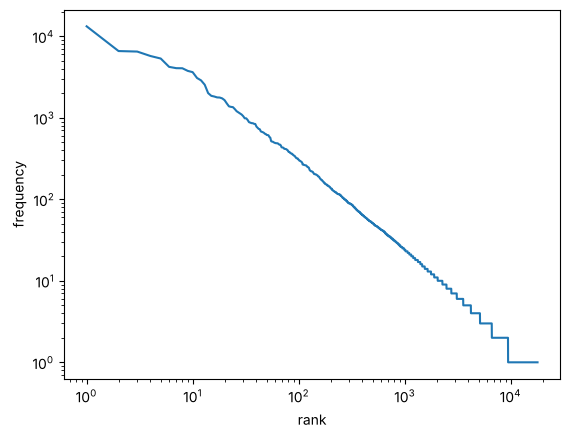

In [3]:
sample = df.sample(n=min(SAMPLE_SIZE, len(df)), random_state=SEED)
counter = Counter(w for t in sample['review'] for w in words(t))
tokens = sum(counter.values())
print('tokens:', tokens, 'types:', len(counter), 'TTR:', round(len(counter)/tokens, 4))
print(counter.most_common(15))
freqs = sorted(counter.values(), reverse=True)
plt.loglog(range(1, len(freqs)+1), freqs)
plt.xlabel('rank'); plt.ylabel('frequency'); plt.show()

## Messy text examples

In [4]:
from src.explore import messy_examples
import pandas as pd
pd.DataFrame(messy_examples(df))

,issue,reviews_affected,share_pct,example
0,HTML line-break tags,29202,58.40,"ey are right, as this is exactly what happened..."
1,URLs,195,0.39,"'S GUIDE TO AN INCONVENIENT TRUTH"" can be foun..."
2,ALL-CAPS emphasis,11339,22.68,which totally ruins all the film! I expected t...
3,Repeated punctuation,12662,25.32,"gangstas, Latinos, Christians, Italians, Irish..."
4,Non-ASCII characters,4660,9.32,that has been done and redone so many times th...
5,Irregular spacing,3986,7.97,"rise really that in the 1990s, a glut of 'Die ..."
6,Rating expressions,2980,5.96,"ly hilarious at the same time, I'm giving this..."


## Tokenizer comparison

In [5]:
from src.tokenization import TOKENIZERS, SENTENCES
for s in SENTENCES:
    print(s)
    for name, fn in TOKENIZERS.items():
        print(f'  {name:<24}', fn(s))

I couldn't believe it; the acting was top-notch, but the plot isn't great.<br /><br />Rated 7.5/10!
  Whitespace split         ['I', "couldn't", 'believe', 'it;', 'the', 'acting', 'was', 'top-notch,', 'but', 'the', 'plot', "isn't", 'great.<br', '/><br', '/>Rated', '7.5/10!']
  Regex \b\w+\b            ['I', 'couldn', 't', 'believe', 'it', 'the', 'acting', 'was', 'top', 'notch', 'but', 'the', 'plot', 'isn', 't', 'great', 'br', 'br', 'Rated', '7', '5', '10']
  NLTK (Treebank-style)    ['I', 'could', "n't", 'believe', 'it', ';', 'the', 'acting', 'was', 'top-notch', ',', 'but', 'the', 'plot', 'is', "n't", 'great.', '<', 'br', '/', '>', '<', 'br', '/', '>', 'Rated', '7.5/10', '!']
  spaCy (English rules)    ['I', 'could', "n't", 'believe', 'it', ';', 'the', 'acting', 'was', 'top', '-', 'notch', ',', 'but', 'the', 'plot', 'is', "n't", 'great.<br', '/><br', '/>Rated', '7.5/10', '!']
Check www.imdb.com for the cast's full list... they're amazing!!!
  Whitespace split         ['Check', 'www.imd

## Cleaning function

In [6]:
from src.clean_text import clean_text
for text in df['review'].head(3):
    print(text[:250])
    print('->', clean_text(text)[:250])
    print()

One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of 
-> one review mention watch 1 oz episod hook right exactli happen first thing struck oz brutal unflinch scene violenc set right word go trust not show faint heart timid show pull no punch regard drug sex violenc hardcor classic use word call oz nicknam 

A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire piece. <br /><br />The actors are extremely well chosen
-> wonder littl product film techniqu veri unassum veri old time bbc fashion give comfort sometim discomfort sens realism entir piec actor extrem well chosen michael sheen not onli got polari but voic pat too truli see seamless edit guid refer